# 04 · U4 nvblox 충돌 세계 — Occupancy / TSDF / ESDF와 "Unknown ≠ Free"

**학습 목표**

1. 깊이 관측이 voxel 지도(occupancy, TSDF)로 쌓이고 ESDF 거리장으로 바뀌는 과정을 2D 토이로 직접 구현한다.
2. 로봇 충돌 구의 **중심 한 점**에서 거리장을 질의하는 구조 때문에, 미관측(unknown) 영역에 중심이 있으면 비용이 0이 될 수 있음을 재현한다. → Baseline R이 손을 충분히 피하지 못한 원인.
3. 같은 상황에서 ROI 관측점까지 거리를 직접 재면 비용이 생긴다는 것(U5의 손 전용 비용이 필요했던 이유)을 확인한다.
4. decay가 없을 때 남는 ghost obstacle과 decay를 넣었을 때의 차이를 본다.
5. 실제 레포 코드(`hand_experiment.py`, `target_margin.py`, cuRobo `world_blox.py`)와 진단 CSV를 연결한다.

**노션에서 정리한 내용과의 연결 (U4)**

| 노션에서 이미 정리한 것 | 이 노트에서 더하는 것 |
|---|---|
| Voxel = 3D grid 한 셀, 크기는 `voxel_size` | 이 실험의 voxel 크기 0.03 m와 **integrator가 `occupancy`** 라는 점 (TSDF 아님) |
| Occupied / Free / Unknown, `Unknown ≠ Free` | unknown 칸에서 거리 질의가 sentinel(−100)을 돌려주고 비용이 0이 되는 흐름 |
| TSDF = 표면 근처 누적·융합, ESDF = 넓은 영역 거리 | 노이즈 프레임 융합 효과를 숫자로 확인, ESDF를 `distance_transform_edt`로 계산 |
| 동적 물체의 ghost obstacle / decay 확인 필요 | 토이에서 decay 유무 비교. decay는 잔상을 **free가 아니라 unknown 쪽으로** 보낸다 |

> 이 노트의 2D 모델은 개념 확인용이다. nvblox의 실제 갱신 계수, decay 규칙, sentinel 처리 위치는 nvblox/nvblox_torch CUDA 소스를 봐야 확정할 수 있고, 그 부분은 마지막 체크리스트에 따로 적었다.

In [1]:
from common import *
plt = setup_plot()
import numpy as np
from scipy.ndimage import distance_transform_edt
import csv
check_paths()

REPO      OK  ~/franka-depth-mppi
CUROBO    OK  ~/curobo
TAPE      OK  ~/franka-depth-mppi/data/hand-tape-20261012-000004-472steps-registered
EVIDENCE  OK  ~/franka-depth-mppi/evidence


## 1. 2D 세계와 깊이 카메라 레이캐스팅

- 격자: 1 cm 칸, x 0–1.0 m(카메라 광축 방향), y 0–0.8 m(위아래).
- 장애물: x=0.55 m에 두께 2 cm, 높이 y 0.30–0.50 m인 "손바닥" + x=0.95 m의 배경 벽.
- 카메라: (0.05, 0.40)에서 +x를 바라보고 시야각 70°, 광선 160개.
- **깊이 미반환 구간**: 실제 D435i에서 손끝 위쪽 영역은 깊이 값이 0(무효)으로 들어왔다(docs/diagnosis.md). 토이에서는 광선 각도 11.5°–22° 구간을 무효로 만든다.

2D라서 "깊이"는 광선 방향 거리(range)로 단순화했다. 실제 카메라는 광축 방향 z 값을 준다.

유효 깊이 광선 86 / 160


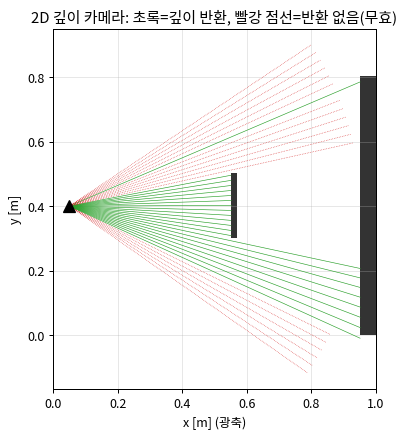

In [2]:
RES = 0.01
NX, NY = 100, 80
CAM = np.array([0.05, 0.40])
FOV = np.deg2rad(70)
NRAY = 160
ANGLES = np.linspace(-FOV / 2, FOV / 2, NRAY)
DROPOUT = (np.deg2rad(11.5), np.deg2rad(22.0))   # 손끝 위 깊이 미반환 흉내

def cell(p):
    return int(p[0] / RES), int(p[1] / RES)

def make_world(boxes):
    """boxes: [(x0, x1, y0, y1), ...] [m] 를 점유로 채운 bool 격자."""
    occ = np.zeros((NX, NY), bool)
    for x0, x1, y0, y1 in boxes:
        occ[int(round(x0 / RES)):int(round(x1 / RES)), int(round(y0 / RES)):int(round(y1 / RES))] = True
    return occ

PALM = (0.55, 0.57, 0.30, 0.50)
WALL = (0.95, 1.00, 0.00, 0.80)
truth = make_world([PALM, WALL])

def raycast(occ, noise=0.0, dropout=DROPOUT, rng=None):
    """각 광선의 첫 점유 칸까지 거리. 반환 없음은 nan."""
    depths = np.full(NRAY, np.nan)
    for i, a in enumerate(ANGLES):
        d = np.array([np.cos(a), np.sin(a)])
        for r in np.arange(0.02, 1.3, RES / 4):
            ix, iy = cell(CAM + r * d)
            if not (0 <= ix < NX and 0 <= iy < NY):
                break
            if occ[ix, iy]:
                depths[i] = r
                break
    if dropout is not None:
        depths[(ANGLES > dropout[0]) & (ANGLES < dropout[1])] = np.nan
    if noise:
        depths = depths + rng.normal(0, noise, NRAY)
    return depths

depths = raycast(truth)
print('유효 깊이 광선', np.isfinite(depths).sum(), '/', NRAY)

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.imshow(truth.T, origin='lower', extent=[0, 1, 0, 0.8], cmap='Greys', alpha=0.8)
for a, dep in zip(ANGLES[::4], depths[::4]):
    d = np.array([np.cos(a), np.sin(a)])
    if np.isfinite(dep):
        e = CAM + dep * d
        ax.plot([CAM[0], e[0]], [CAM[1], e[1]], color='tab:green', lw=0.5)
    else:
        e = CAM + 0.9 * d
        ax.plot([CAM[0], e[0]], [CAM[1], e[1]], color='tab:red', lw=0.5, ls=':')
ax.plot(*CAM, 'k^', ms=10)
ax.set_title('2D 깊이 카메라: 초록=깊이 반환, 빨강 점선=반환 없음(무효)')
ax.set_xlabel('x [m] (광축)'); ax.set_ylabel('y [m]')
plt.show()

## 2. Occupancy 지도 (log-odds)

광선 하나가 주는 정보:

- 카메라 ~ 표면 직전 칸: "비어 있다" → $l \leftarrow l + l_{free}$ ($l_{free}<0$)
- 표면 칸: "차 있다" → $l \leftarrow l + l_{occ}$ ($l_{occ}>0$)
- 표면 뒤: 정보 없음 (가려짐)
- **깊이 반환이 없는 광선: 아무 칸도 갱신하지 않는다.** "거기까지 비었다"는 근거도 없기 때문이다.

$l = \log\frac{p}{1-p}$ 이므로 $l>0$이면 점유 확률 > 0.5. 여기서는 한 번도 갱신되지 않은 칸을 unknown으로 둔다.

free / occupied / unknown 칸 수: [1808, 46, 6146]


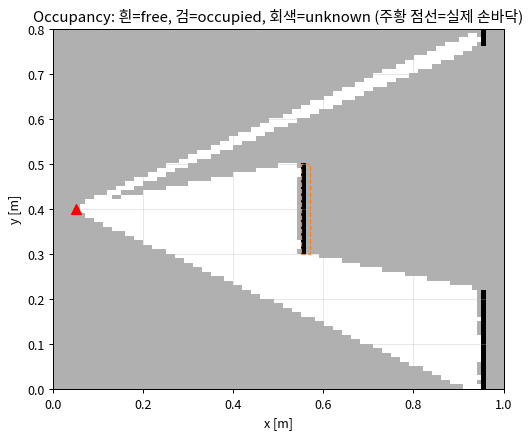

In [3]:
L_FREE, L_OCC, L_MIN, L_MAX = -0.4, 0.85, -2.0, 3.5

def integrate_occupancy(logodds, observed, depths):
    for a, dep in zip(ANGLES, depths):
        if not np.isfinite(dep):
            continue                          # 무효 깊이: 갱신 없음
        d = np.array([np.cos(a), np.sin(a)])
        free = {cell(CAM + r * d) for r in np.arange(0.02, dep - RES, RES / 4)}
        hit = cell(CAM + dep * d)
        free.discard(hit)
        for c in free:
            if 0 <= c[0] < NX and 0 <= c[1] < NY:
                logodds[c] += L_FREE; observed[c] = True
        if 0 <= hit[0] < NX and 0 <= hit[1] < NY:
            logodds[hit] += L_OCC; observed[hit] = True
    np.clip(logodds, L_MIN, L_MAX, out=logodds)

def classify(logodds, observed):
    """0=free, 1=occupied, 2=unknown"""
    s = np.full(logodds.shape, 2)
    s[observed & (logodds < 0)] = 0
    s[observed & (logodds > 0)] = 1
    return s

logodds = np.zeros((NX, NY)); observed = np.zeros((NX, NY), bool)
for _ in range(5):
    integrate_occupancy(logodds, observed, raycast(truth))
state = classify(logodds, observed)
print('free / occupied / unknown 칸 수:', [(state == k).sum() for k in range(3)])

from matplotlib.colors import ListedColormap
STATE_CMAP = ListedColormap(['white', 'black', '#b0b0b0'])
def show_state(ax, state, title, palm=True):
    ax.imshow(state.T, origin='lower', extent=[0, 1, 0, 0.8], cmap=STATE_CMAP, vmin=0, vmax=2)
    ax.plot(*CAM, 'r^', ms=8)
    if palm:
        x0, x1, y0, y1 = PALM
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='tab:orange', lw=1, ls='--'))
    ax.set_title(title); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')

fig, ax = plt.subplots(figsize=(7, 5.2))
show_state(ax, state, 'Occupancy: 흰=free, 검=occupied, 회색=unknown (주황 점선=실제 손바닥)')
plt.show()

회색 영역 세 가지를 구분해 두자.

1. **시야 밖** (위·아래 바깥)
2. **손바닥 뒤 가림 영역** (손바닥과 벽 사이)
3. **깊이 미반환 쐐기** (손바닥 위쪽으로 뻗은 회색 띠)

셋 다 "모른다"이지 "비어 있다"가 아니다. 2와 3이 실제 실험에서 Baseline 실패의 원인이었다.

## 3. TSDF — 여러 노이즈 프레임 융합

칸 중심까지 거리 $r$, 같은 방향 광선의 측정 깊이 $D$에 대해

$$ sdf = D - r,\qquad tsdf = \mathrm{clip}(sdf, -\tau, \tau)$$

$sdf < -\tau$ (표면보다 한참 뒤)는 가려진 영역이라 갱신하지 않는다. 프레임마다 가중 평균:

$$ T \leftarrow \frac{W T + w\, tsdf}{W + w},\quad W \leftarrow W + w $$

표면은 $T=0$이 되는 위치. 노이즈 σ=6 mm 깊이로 단일 프레임과 20프레임 융합의 표면 위치 오차를 비교한다.

> 이 실험(`hand_experiment.py:93`)은 `integrator_type: 'occupancy'`를 쓴다. TSDF는 노션에서 공부한 개념을 확인하는 용도로만 넣었다.

 1 프레임 융합: 표면 위치 오차 RMS = 5.60 mm
20 프레임 융합: 표면 위치 오차 RMS = 2.25 mm


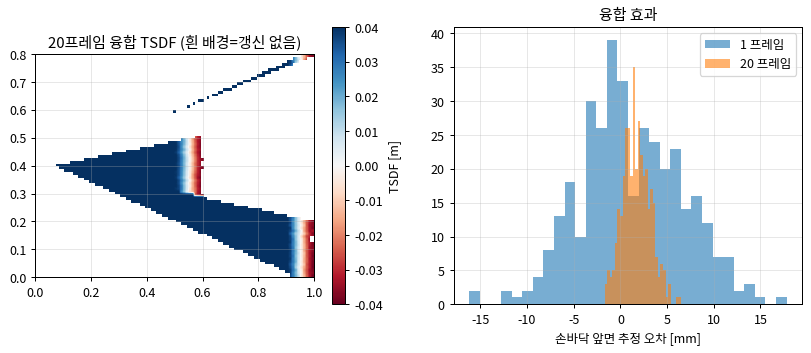

In [4]:
TAU = 0.04
gx, gy = np.meshgrid((np.arange(NX) + 0.5) * RES, (np.arange(NY) + 0.5) * RES, indexing='ij')
cell_r = np.hypot(gx - CAM[0], gy - CAM[1])
cell_a = np.arctan2(gy - CAM[1], gx - CAM[0])
cell_ray = np.round((cell_a + FOV / 2) / (FOV / (NRAY - 1))).astype(int)
in_fov = (cell_ray >= 0) & (cell_ray < NRAY)
cell_ray = np.clip(cell_ray, 0, NRAY - 1)

def integrate_tsdf(T, W, depths):
    D = depths[cell_ray]
    sdf = D - cell_r
    ok = in_fov & np.isfinite(D) & (sdf > -TAU)
    t = np.clip(sdf, -TAU, TAU)
    T[ok] = (W[ok] * T[ok] + t[ok]) / (W[ok] + 1)
    W[ok] += 1

def palm_front_estimate(T, W):
    """손바닥 높이의 각 행에서 x 방향 첫 zero-crossing (선형 보간)."""
    est = []
    for iy in range(int(PALM[2] / RES) + 1, int(PALM[3] / RES) - 1):
        col, w = T[:, iy], W[:, iy]
        for ix in range(30, 70):
            if w[ix] > 0 and w[ix + 1] > 0 and col[ix] > 0 >= col[ix + 1]:
                x0, x1 = gx[ix, iy], gx[ix + 1, iy]
                est.append(x0 + (x1 - x0) * col[ix] / (col[ix] - col[ix + 1]))
                break
    return np.array(est)

rng = np.random.default_rng(0)
errs = {}
for n in [1, 20]:
    e_all = []
    for trial in range(20):
        T = np.zeros((NX, NY)); W = np.zeros((NX, NY))
        for _ in range(n):
            integrate_tsdf(T, W, raycast(truth, noise=0.006, rng=rng))
        e_all.append(palm_front_estimate(T, W) - PALM[0])
    errs[n] = np.concatenate(e_all)
    print(f'{n:2d} 프레임 융합: 표면 위치 오차 RMS = {1000*np.sqrt(np.mean(errs[n]**2)):.2f} mm')

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
im = axs[0].imshow(np.where(W > 0, T, np.nan).T, origin='lower', extent=[0, 1, 0, 0.8], cmap='RdBu', vmin=-TAU, vmax=TAU)
plt.colorbar(im, ax=axs[0], label='TSDF [m]')
axs[0].set_title('20프레임 융합 TSDF (흰 배경=갱신 없음)')
axs[1].hist(1000 * errs[1], bins=30, alpha=0.6, label='1 프레임')
axs[1].hist(1000 * errs[20], bins=30, alpha=0.6, label='20 프레임')
axs[1].set_xlabel('손바닥 앞면 추정 오차 [mm]'); axs[1].legend(); axs[1].set_title('융합 효과')
plt.show()

오차가 줄어드는 이유는 "먼 데이터를 버려서"가 아니라 같은 표면을 여러 번 본 측정을 평균했기 때문이다(노션 U4 정정 내용과 같음). truncation $\tau$는 표면에서 먼 칸을 갱신하지 않게 해 계산량을 줄이고 가려진 영역을 보호한다. 셀 크기가 1 cm라 남는 오차에는 양자화 성분도 섞여 있다.

## 4. ESDF와 sentinel

ESDF는 각 칸에서 가장 가까운 점유 칸까지의 유클리드 거리다. 부호는 바깥 +, 안쪽 −로 둔다.

$$ d(\mathbf x) = \mathrm{EDT}(\neg occ)(\mathbf x) - \mathrm{EDT}(occ)(\mathbf x)$$

토이에서는 unknown 칸의 질의값을 **−100**으로 둔다. 실제 실험에서 미관측 위치의 raw ESDF가 −100으로 돌아왔다(docs/diagnosis.md: "−100: 미관측/질의 불가 sentinel, 실제 −100 m 거리가 아님"). 이 값을 거리로 읽으면 "깊숙이 충돌"이 되지만, 실제 비용 경로에서는 해당 구의 nvblox 비용이 0이었다.

> 주의: 일반 SDF의 부호(바깥 +)와 cuRobo 충돌 API의 반환 부호(충돌 안쪽 +)는 다르다. 아래는 개념용 일반 SDF 부호다.

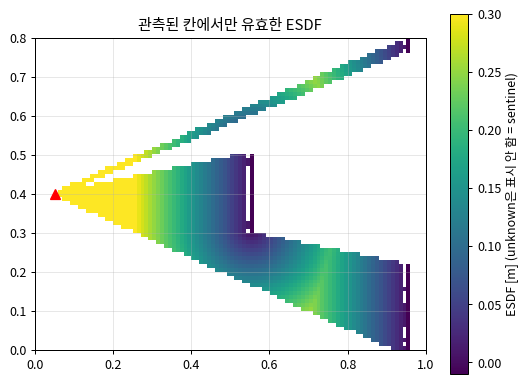

In [5]:
SENTINEL = -100.0
occ_map = state == 1
esdf = distance_transform_edt(~occ_map) * RES - distance_transform_edt(occ_map) * RES
esdf_raw = np.where(state == 2, SENTINEL, esdf)

def query(esdf_raw, p):
    ix, iy = cell(p)
    return esdf_raw[ix, iy]

fig, ax = plt.subplots(figsize=(7, 5.2))
im = ax.imshow(np.where(esdf_raw <= -99, np.nan, esdf_raw).T, origin='lower', extent=[0, 1, 0, 0.8], cmap='viridis', vmax=0.3)
plt.colorbar(im, ax=ax, label='ESDF [m] (unknown은 표시 안 함 = sentinel)')
ax.plot(*CAM, 'r^', ms=8)
ax.set_title('관측된 칸에서만 유효한 ESDF')
plt.show()

## 5. 핵심 데모 — 구 중심 질의 vs ROI 관측점 거리

cuRobo의 환경 비용은 충돌 구마다 **구 중심의 거리값**에서 반지름을 빼 간격을 만든다.

$$ gap = d(\mathbf c) - r,\qquad C = w\,\phi_\eta(gap) $$

$\phi_\eta$는 `common.eta_cost` (U3에서 본 activation-distance 비용). 두 구를 놓아 본다. 둘 다 반지름 70 mm(= Franka 원래 50 mm + 계획 buffer 20 mm, step163 panda_link5 sphere 30과 같은 크기)이다.

- **구 A**: 중심이 손끝 위 깊이 미반환 쐐기 안. 구 표면은 손바닥 위 끝과 겹친다.
- **구 B**: 중심이 손바닥 뒤 가림 영역. 구 표면은 손바닥 앞면 관측점과 겹친다(그리퍼 중심이 손바닥 뒤에 있던 경우).

비교 대상은 ROI 상자 안의 실제 깊이 반환점까지 거리를 직접 재는 방식(U5의 손 전용 비용 방식)이다.

ROI 관측점 수: 52
구                  중심 상태     raw ESDF    ESDF 비용   ROI 간격[mm]     ROI 비용
A (손끝 위 미반환)       unknown   -100.000        0.0        -11.1     2361.6
B (손바닥 뒤 가림)       unknown   -100.000        0.0        -22.1     3462.7


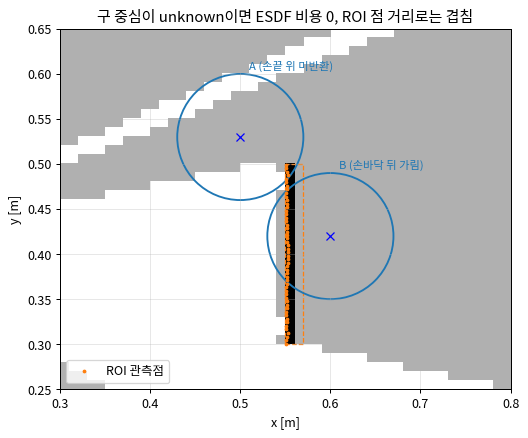

In [6]:
W_ENV, ETA = 1e5, 0.025
spheres = {'A (손끝 위 미반환)': (np.array([0.50, 0.53]), 0.07),
           'B (손바닥 뒤 가림)': (np.array([0.60, 0.42]), 0.07)}

# ROI 관측점: 깊이 반환점 중 손 주변 상자 안에 있는 것
pts = np.array([CAM + dep * np.array([np.cos(a), np.sin(a)]) for a, dep in zip(ANGLES, depths) if np.isfinite(dep)])
ROI = (0.45, 0.65, 0.28, 0.56)
roi_pts = pts[(pts[:, 0] >= ROI[0]) & (pts[:, 0] < ROI[1]) & (pts[:, 1] >= ROI[2]) & (pts[:, 1] < ROI[3])]
print('ROI 관측점 수:', len(roi_pts))

print(f'{"구":18s} {"중심 상태":8s} {"raw ESDF":>9s} {"ESDF 비용":>10s} {"ROI 간격[mm]":>12s} {"ROI 비용":>10s}')
for name, (c, r) in spheres.items():
    raw = query(esdf_raw, c)
    st = ['free', 'occupied', 'unknown'][state[cell(c)]]
    env_cost = 0.0 if raw <= -99 else float(eta_cost(raw - r, ETA, W_ENV))
    gap_roi = np.linalg.norm(roi_pts - c, axis=1).min() - r
    roi_cost = float(eta_cost(gap_roi, ETA, W_ENV))
    print(f'{name:18s} {st:8s} {raw:9.3f} {env_cost:10.1f} {1000*gap_roi:12.1f} {roi_cost:10.1f}')

fig, ax = plt.subplots(figsize=(7, 5.2))
show_state(ax, state, '구 중심이 unknown이면 ESDF 비용 0, ROI 점 거리로는 겹침')
ax.plot(roi_pts[:, 0], roi_pts[:, 1], '.', color='tab:orange', ms=4, label='ROI 관측점')
for name, (c, r) in spheres.items():
    ax.add_patch(plt.Circle(c, r, fill=False, ec='tab:blue', lw=1.5))
    ax.plot(*c, 'bx'); ax.text(c[0] + 0.01, c[1] + 0.075, name, color='tab:blue', fontsize=9)
ax.set_xlim(0.3, 0.8); ax.set_ylim(0.25, 0.65); ax.legend(loc='lower left')
plt.show()

`raw ESDF = −100`을 그대로 거리로 쓰면 오히려 엄청난 충돌 비용이 나와야 한다. 실제로는 sentinel이므로 비용 경로에서 걸러져 0이 된다(토이는 `raw <= −99 → 0`으로 흉내냈다). 즉 **구 외곽이 관측 표면과 겹쳐도, 구 중심 한 점이 미관측이면 환경 비용이 사라진다.** 3 cm 표시 voxel이 화면에 보인다는 사실이 로봇 구 중심에서 ESDF가 유효하다는 뜻은 아니다.

ROI 방식은 관측점 좌표를 직접 장애물(1 mm cuboid)로 넣으므로 구 중심의 지도 상태와 무관하게 거리가 계산된다. 그래서 R→LOW 차이에는 "질량 정책" 효과 말고도 이 **표현 보강 효과**가 섞여 있다. 질량 효과만 보려면 LOW→HIGH를 비교해야 한다.

## 6. 실제 실험 진단 데이터 (Baseline R, step 150–175)

`docs/data/R-nvblox-nearest.csv` 열 의미:

- `clearance_mm`: 손 ROI 관측면과 가장 가까운 구 사이 간격 (**buffer 20 mm 포함**)
- `center_raw_sdf_m`: 그 구 중심의 raw ESDF 질의값
- `all_spheres_nvblox_cost`: 로봇 전체 구의 nvblox 비용 합
- `roi_low_cost`, `roi_high_p1_cost`: 같은 자세를 ROI 방식(η=25 mm / 73.52 mm)으로 평가한 비용

center_raw_sdf_m 고유값: [-100.0]
겹침 step: [158, 159, 160, 161, 162, 163, 164]
겹침 구간 all_spheres_nvblox_cost 합 = 0.0
겹침 구간 roi_low_cost 최대 = 104123.5 / roi_high_p1_cost 최대 = 592362.7
step163: {'link': 'panda_link5', 'sphere_index': '30', 'clearance_mm': '-29.54002097249031', 'center_raw_sdf_m': '-100.0', 'all_spheres_nvblox_cost': '0.0', 'roi_low_cost': '18502.576171875', 'roi_high_p1_cost': '217650.109375', 'feasible': 'True'}


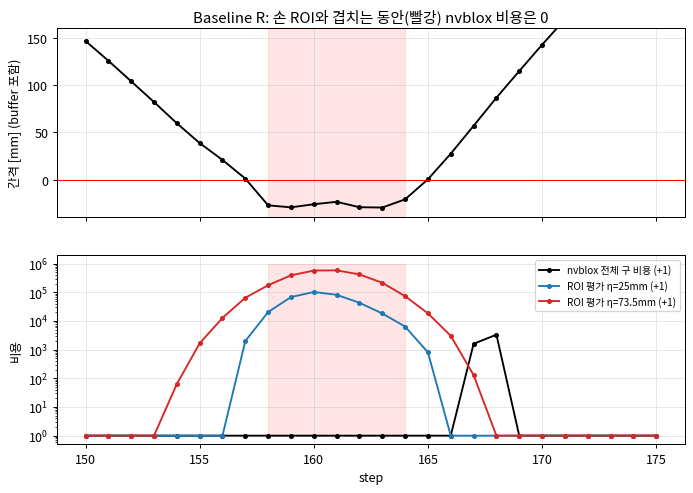

In [7]:
rows = list(csv.DictReader(open(REPO / 'docs/data/R-nvblox-nearest.csv')))
f = lambda k: np.array([float(r[k]) for r in rows])
step = f('step')
print('center_raw_sdf_m 고유값:', sorted(set(f('center_raw_sdf_m'))))
overlap = f('clearance_mm') < 0
print('겹침 step:', step[overlap].astype(int).tolist())
print('겹침 구간 all_spheres_nvblox_cost 합 =', f('all_spheres_nvblox_cost')[overlap].sum())
print('겹침 구간 roi_low_cost 최대 =', f('roi_low_cost')[overlap].max().round(1), '/ roi_high_p1_cost 최대 =', f('roi_high_p1_cost')[overlap].max().round(1))
print('step163:', {k: rows[13][k] for k in ['link', 'sphere_index', 'clearance_mm', 'center_raw_sdf_m', 'all_spheres_nvblox_cost', 'roi_low_cost', 'roi_high_p1_cost', 'feasible']})

fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axs[0].plot(step, f('clearance_mm'), 'k.-')
axs[0].axhline(0, color='r', lw=0.8)
axs[0].fill_between(step, -40, 160, where=overlap, color='r', alpha=0.1)
axs[0].set_ylabel('간격 [mm] (buffer 포함)'); axs[0].set_ylim(-40, 160)
axs[0].set_title('Baseline R: 손 ROI와 겹치는 동안(빨강) nvblox 비용은 0')
axs[1].semilogy(step, f('all_spheres_nvblox_cost') + 1, 'k.-', label='nvblox 전체 구 비용 (+1)')
axs[1].semilogy(step, f('roi_low_cost') + 1, '.-', color=COLORS['LOW'], label='ROI 평가 η=25mm (+1)')
axs[1].semilogy(step, f('roi_high_p1_cost') + 1, '.-', color=COLORS['HIGH'], label='ROI 평가 η=73.5mm (+1)')
axs[1].fill_between(step, 1, 1e6, where=overlap, color='r', alpha=0.1)
axs[1].set_xlabel('step'); axs[1].set_ylabel('비용'); axs[1].legend(fontsize=8)
plt.show()

- 겹침 7시점(step 158–164) 동안 nvblox 비용 합은 0, 같은 자세의 ROI 평가 비용은 수만~수십만.
- step 167–168에는 nvblox 비용이 양수다. 환경 비용 전체가 꺼진 것이 아니라 **손 겹침 위치에서만** 비어 있었다는 근거.
- 모든 행의 중심 raw ESDF가 −100: 가장 가까운 구의 중심이 계속 미관측 영역에 있었다.
- `feasible`은 내내 True. feasible은 반환 명령 상태의 제약 검사이고 이 비용 공백을 잡지 못한다(05에서 다시 정리).

## 7. 동적 지도: ghost obstacle과 decay

물체가 A에서 B로 옮겨간 뒤 A의 앞면 칸(카메라가 실제로 맞히던 칸)이 어떻게 되는지 두 경우로 본다.

- **경우 1 (A가 계속 보임)**: 물체가 옆으로 빠져 A를 지나는 광선이 벽까지 닿는다 → free 갱신이 쌓여 잔상이 지워진다.
- **경우 2 (A가 가려짐)**: 물체가 A 앞쪽으로 옮겨와 A를 가린다 → A를 갱신할 광선이 없다 → decay가 없으면 잔상이 영원히 남는다.

decay 토이 규칙: 매 프레임 적분 전에 모든 칸에 $l \leftarrow \lambda l$ ($\lambda=0.85$). 코드 순서(`hand_experiment.py:245`)도 decay → 적분이다.

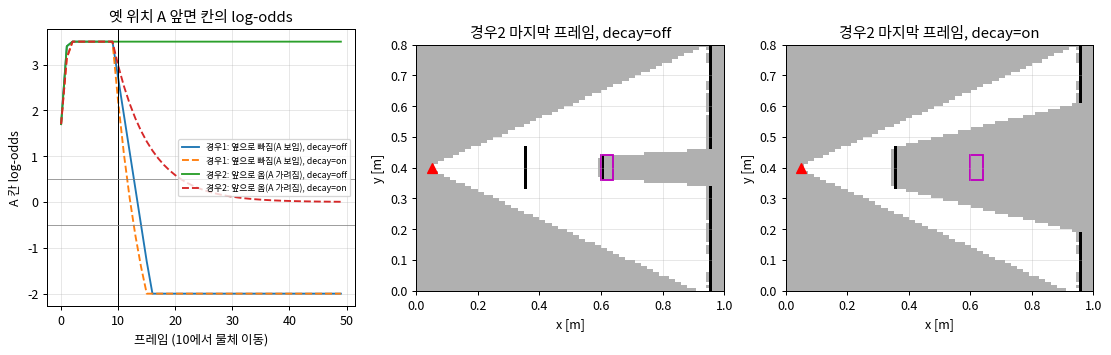

In [8]:
def run_ghost(before, after, decay, n_before=10, n_after=40, lam=0.85, probe=(0.605, 0.40)):
    lo = np.zeros((NX, NY)); ob = np.zeros((NX, NY), bool)
    hist = []
    for k in range(n_before + n_after):
        world = make_world(before if k < n_before else after)
        if decay:
            lo *= lam
        integrate_occupancy(lo, ob, raycast(world, dropout=None))
        hist.append(lo[cell(np.array(probe))])
    return np.array(hist), lo, ob

A_BOX = (0.60, 0.64, 0.36, 0.44)
cases = {'경우1: 옆으로 빠짐(A 보임)': ([A_BOX, WALL], [(0.60, 0.64, 0.60, 0.68), WALL]),
         '경우2: 앞으로 옴(A 가려짐)': ([A_BOX, WALL], [(0.35, 0.38, 0.33, 0.47), WALL])}

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for name, (before, after) in cases.items():
    for decay, ls in [(False, '-'), (True, '--')]:
        h, lo, ob = run_ghost(before, after, decay)
        axs[0].plot(h, ls, label=f'{name}, decay={"on" if decay else "off"}')
        if name.startswith('경우2'):
            show_state(axs[1 if not decay else 2], classify(lo, ob & (np.abs(lo) > 0.5)) if decay else classify(lo, ob),
                       f'경우2 마지막 프레임, decay={"on" if decay else "off"}', palm=False)
            axs[1 if not decay else 2].add_patch(plt.Rectangle((A_BOX[0], A_BOX[2]), 0.04, 0.08, fill=False, ec='m', lw=1.5))
axs[0].axvline(10, color='k', lw=0.8); axs[0].axhline(0.5, color='gray', lw=0.6); axs[0].axhline(-0.5, color='gray', lw=0.6)
axs[0].set_xlabel('프레임 (10에서 물체 이동)'); axs[0].set_ylabel('A 칸 log-odds'); axs[0].legend(fontsize=7)
axs[0].set_title('옛 위치 A 앞면 칸의 log-odds')
plt.show()

읽는 법:

- 경우 1은 decay가 없어도 free 광선이 잔상을 지운다(log-odds가 음수로 내려감).
- 경우 2, decay off: A의 log-odds가 양수 그대로 → **ghost obstacle** (가운데 그림의 자홍 상자 안 검은 칸).
- 경우 2, decay on: log-odds가 0 근처로 줄어 점유 판정에서 빠진다. 하지만 free가 된 것은 아니다. 오른쪽 그림에서는 |l|≤0.5를 unknown(회색)으로 그렸다. **decay는 "모른다"로 되돌릴 뿐, 비어 있다는 근거를 만들지 않는다.**

손을 고정한 이번 최종 실험(정적 장면)에서는 ghost 문제가 결과에 주는 영향이 작다. 손을 움직이는 동적 실험으로 넘어가면 decay 계수와 관측 상실 처리를 다시 봐야 한다.

## 8. 실제 코드 연결

### 8.1 지도 설정 — `experiment/hand_experiment.py:93`, `:99`

In [9]:
show_code(REPO / 'experiment/hand_experiment.py', 93, 99, width=200)

   93| worldcfg=WorldConfig.from_dict({'blox':{'world':{'pose':[0,0,0,1,0,0,0],'integrator_type':'occupancy','voxel_size':scene['map_voxel_m']}}})
   94| if args.without_camera_map:worldcfg=WorldConfig()
   95| fixed=WorldConfig.from_dict(load_yaml(join_path(get_world_configs_path(),'collision_wall.yml')));fixed.cuboid[0].pose[2]-=.01
   96| for obj in fixed.cuboid[:2]:worldcfg.add_obstacle(obj)
   97| from curobo.util.usd_helper import UsdHelper
   98| usd=UsdHelper();usd.load_stage(stage);usd.add_world_to_stage(fixed.get_mesh_world(),base_frame='/World')
   99| for i in range(cfg['proxy_capacity']):worldcfg.add_obstacle(Cuboid(name='target_margin_%02d'%i,pose=[10,0,0,1,0,0,0],dims=cfg['nominal_point_proxy_dims_m']))


- `integrator_type: 'occupancy'`, `voxel_size = scene['map_voxel_m']` = 0.03 m (`scene.json`).
- 고정 벽·테이블(`collision_wall.yml`의 cuboid 2개)도 같은 world에 들어간다 → 환경 비용 = blox + primitive 합.
- `target_margin_XX` cuboid 64개도 world에 추가되지만 `TargetMargin(..., margin=0.)`이라 비활성이다(`target_margin.py`에서 `enabled = observed and margin>0`). 손 전용 비용은 별도의 `WorldPrimitiveCollision`(05 노트)으로 계산한다.

### 8.2 깊이 프레임 반영 순서 — `hand_experiment.py:244-246`

In [10]:
show_code(REPO / 'experiment/hand_experiment.py', 244, 246, width=260)

  244|   data=source.get_data(step);d=data['depth'];d[:24,:]=0;d[456:,:]=0;d[:,:32]=0;d[:,608:]=0
  245|   checker.decay_layer('world');checker.add_camera_frame(CameraObservation(depth_image=d,intrinsics=data['intrinsics'],pose=cam).to(device=ta.device),'world');checker.process_camera_frames('world',False);torch.cuda.synchronize();checker.update_blox_hashes();tor ...
  246|   observer.update(data,checker._blox_mapper,R,t);channel.update(observer.anchors);map_steps.append(step)


map_step마다 순서는 **가장자리 마스크 → `decay_layer` → `add_camera_frame` → `process_camera_frames` → `update_blox_hashes`** 다. 그 다음에 같은 프레임으로 ROI anchor를 뽑고(`observer.update`) 손 비용 슬롯을 갱신한다(`channel.update`). docs/method.md는 이를 "occupancy decay→깊이 적분→ESDF→동기화→hash 갱신"으로 적고 있다.

### 8.3 ROI anchor의 sdf 필터 — `experiment/target_margin.py:33-35`

In [11]:
show_code(REPO / 'experiment/target_margin.py', 33, 35, width=200)

   33|         if len(anchors):
   34|             query=torch.cat([self.ta.to_device(anchors),torch.zeros((len(anchors),1),device="cuda")],dim=-1).contiguous();d=mapper.query_sdf(query,mapper_id=0)
   35|             anchors=anchors[((d>-99)&(d.abs()<=.06)).cpu().numpy()]


`d > -99`가 바로 sentinel 거르기다. 이 필터는 **anchor 후보**에 대해 "nvblox가 이 점을 알고 있고(관측됨) 표면 근처(|d| ≤ 6 cm)인가"를 본다. 손 관측점 자체는 표면 voxel이라 대부분 통과한다(diagnosis: 가장 가까운 손 관측점 raw ESDF = 0). 실패한 쪽은 손 관측점이 아니라 **로봇 구 중심**의 질의였다.

### 8.4 cuRobo 쪽 비용 경로 — `curobo/geom/sdf/world_blox.py`

In [12]:
show_code(CUROBO / 'src/curobo/geom/sdf/world_blox.py', 179, 205)
print('...')
show_code(CUROBO / 'src/curobo/geom/sdf/world_blox.py', 702, 712)

  179|         d = self._get_blox_sdf(
  180|             query_sphere,
  181|             collision_query_buffer,
  182|             weight=weight,
  183|             activation_distance=activation_distance,
  184|             return_loss=return_loss,
  185|             compute_esdf=compute_esdf,
  186|         )
  187| 
  188|         if ("primitive" not in self.collision_types or not self.collision_types["primitive"]) and (
  189|             "mesh" not in self.collision_types or not self.collision_types["mesh"]
  190|         ):
  191|             return d
  192|         d_base = super().get_sphere_distance(
  193|             query_sphere,
  194|             collision_query_buffer,
  195|             weight,
  196|             activation_distance,
  197|             env_query_idx,
  198|             return_loss,
  199|             sum_collisions=sum_collisions,
  200|             compute_esdf=compute_esdf,
  201|         )
  202|         if compute_esdf:
  203|             d = tor

- `_get_blox_sdf` → `self._blox_mapper.query_sphere_sdf_cost(...)` : 구 [x, y, z, r]을 nvblox_torch CUDA 커널에 넘겨 비용을 받는다.
- blox 결과 `d`와 primitive(벽·테이블) 결과 `d_base`를 더한다 (`d = d + d_base`).
- sentinel(−100)을 비용 0으로 만드는 분기는 **nvblox_torch의 `query_sphere_sdf_cost` 커널 안**에 있다. 이 저장소/cuRobo 파이썬 코드에서는 보이지 않으므로, 정확한 조건(블록 미할당 vs observed=false)은 아직 확인하지 않은 항목이다.

## 9. 정정·확인 포인트

| 이전 이해 / 질문 | 이 노트에서 확인한 것 |
|---|---|
| nvblox가 TSDF로 표면을 만든 뒤 ESDF 계산 | 이 실험 설정은 `integrator_type='occupancy'` (voxel 0.03 m). TSDF는 일반 개념으로만 확인 |
| 손이 지도에 보이면 환경 비용이 손을 피하게 한다 | 비용은 **구 중심** 거리값 기반. 중심이 미관측이면 구가 손과 겹쳐도 비용 0 (R step 158–164) |
| raw ESDF −100 = 매우 깊은 충돌 | 미관측/질의 불가 sentinel. 거리로 해석하면 안 된다 |
| decay를 켜면 잔상이 사라져 free가 된다 | decay는 log-odds를 0 쪽(불확실)으로 되돌린다. free 근거는 새 free 광선이 있어야 생긴다 |
| R에는 손 회피 비용이 없다 | R에도 nvblox 환경 비용 경로는 있다. 손 근접 위치에서 관측 공백으로 실제 값이 0이었다 |
| `feasible=True`면 손과 안 겹친다 | 겹침 구간 내내 feasible=True. 제약 검사에 이 비용 공백이 반영되지 않는다 |

## 10. 노션 U4 체크리스트 — 답한 것 / 남은 것

| 체크리스트 항목 | 상태 |
|---|---|
| Depth image의 지도 반영 과정 (`experiment.py:54-59, 136-139` → 최종본은 `hand_experiment.py:244-246`) | 답함: 8.2절 순서 |
| 실제 사용하는 TSDF / occupancy / ESDF layer | 답함: occupancy integrator + ESDF 질의 (8.1절) |
| `world_blox.py get_sphere_distance` 이후 질의 경로 | 파이썬 부분 답함: `_get_blox_sdf` → `query_sphere_sdf_cost` (8.4절). 커널 내부는 남음 |
| nvblox CUDA query 안의 `activation_distance` 비용식 | **남음**: nvblox_torch 커널 확인 필요. cuRobo primitive 커널식(`sphere_obb_kernel.cu`)과 같은지 비교 |
| sphere–OBB 비용식과 nvblox 비용식의 차이 | **남음** (위와 같은 이유) |
| 물체 제거 후 decay·잔상·삭제 조건 | 개념은 7절 토이로 확인. 실제 decay 계수와 규칙은 **남음** |
| unknown space가 collision query에서 어떻게 취급되는가 | 현상은 답함: raw −100, 비용 0 (6절). 블록 미할당과 observed=false 구분은 **남음** (diagnosis.md도 "raw sentinel만으로 구분하지 못했다"고 적음) |

## 복습 질문

<details><summary>1. 깊이 반환이 없는 광선에 대해 occupancy를 갱신하지 않는 이유는?</summary>

반환이 없으면 표면이 어디인지는 물론 "어디까지 비었는지"도 모른다. 최대 거리까지 free로 칠하면 손끝처럼 실제 물체가 있는데 반사가 안 된 영역을 free로 잘못 만들 수 있다.
</details>

<details><summary>2. 구 외곽이 관측 손 표면과 30 mm 겹치는데 nvblox 비용이 0일 수 있는 이유는?</summary>

환경 비용은 구 중심 한 점의 ESDF 값으로 계산된다. 중심이 깊이 미반환 영역이나 손바닥 뒤 가림 영역에 있으면 질의값이 sentinel(−100)이고 그 구의 비용은 0이 된다.
</details>

<details><summary>3. ROI 손 전용 비용은 이 문제를 어떻게 피하는가?</summary>

관측된 손 점의 좌표를 1 mm cuboid 장애물로 직접 넣고 구와 cuboid 사이 거리를 계산한다. 구 중심 위치의 지도 상태와 상관없이 거리가 나온다. 대신 손 뒷면처럼 관측되지 않은 부분은 여전히 표현하지 못한다.
</details>

<details><summary>4. R→LOW와 LOW→HIGH 비교가 의미하는 바가 다른 이유는?</summary>

R→LOW는 손 표현 자체(관측 공백 보완)와 추가 비용 도입이 함께 바뀐다. LOW→HIGH는 같은 ROI 표현에서 η만 바뀌므로 질량 가정의 효과만 비교한다.
</details>

<details><summary>5. decay를 강하게 하면 생기는 부작용은?</summary>

계속 보이는 물체도 매 프레임 다시 적분해야 점유가 유지된다. 깊이 노이즈나 일시적 미반환으로 한두 프레임 관측이 빠지면 장애물이 금방 "불확실"로 내려가 비용이 약해질 수 있다.
</details>

---
**다음:** `05_U5_hand_roi_cost.ipynb` — 실제 깊이 기록에서 ROI anchor를 재현하고, 질량→η 정책과 손 비용이 MPPI에 연결되는 방식을 본다.